In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Deixar os gráficos do matplotlib mais bonitos no notebook
%matplotlib inline



In [ ]:
# Lendo o dataset diretamente do GitHub
url_dados = "https://raw.githubusercontent.com/alura-cursos/data_science_projeto/main/Dados/bicicletas.csv"
df = pd.read_csv(url_dados)

# Visualizando as primeiras linhas
df.head()

,data_hora,contagem,temperatura,sensacao_termica,umidade,velocidade_vento,clima,feriado,fim_de_semana,estacao
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,Nublado,Não,Sim,Inverno
1,2015-01-04 01:00:00,138,NaN,NaN,93.0,5.0,Céu limpo,Não,Sim,Inverno
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,Céu limpo,Não,Sim,Inverno
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,Céu limpo,Não,Sim,Inverno
4,2015-01-04 04:00:00,47,NaN,NaN,93.0,6.5,Céu limpo,Não,Sim,Inverno


In [ ]:
# Informações gerais sobre o DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17429 entries, 0 to 17428
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   data_hora         17429 non-null  object 
 1   contagem          17429 non-null  int64  
 2   temperatura       17406 non-null  float64
 3   sensacao_termica  17406 non-null  float64
 4   umidade           17429 non-null  float64
 5   velocidade_vento  17429 non-null  float64
 6   clima             17429 non-null  object 
 7   feriado           17429 non-null  object 
 8   fim_de_semana     17429 non-null  object 
 9   estacao           17429 non-null  object 
dtypes: float64(4), int64(1), object(5)
memory usage: 1.3+ MB


In [ ]:
# Quantidade de valores faltantes por coluna
df.isnull().sum()

,0
data_hora,0
contagem,0
temperatura,23
sensacao_termica,23
umidade,0
velocidade_vento,0
clima,0
feriado,0
fim_de_semana,0
estacao,0


In [ ]:
# Tratando valores faltantes de forma numérica (interpolação)
df['temperatura'] = df['temperatura'].interpolate(method='linear')
df['sensacao_termica'] = df['sensacao_termica'].interpolate(method='linear')

# Conferindo novamente valores faltantes
df.isnull().sum()

,0
data_hora,0
contagem,0
temperatura,0
sensacao_termica,0
umidade,0
velocidade_vento,0
clima,0
feriado,0
fim_de_semana,0
estacao,0


In [ ]:
# Verificando quantidade de linhas duplicadas
df.duplicated().sum()

np.int64(15)

In [ ]:
# Visualizando as linhas duplicadas, se existirem
linhas_duplicadas = df[df.duplicated(keep=False)].sort_values(by='data_hora')
linhas_duplicadas.head()

,data_hora,contagem,temperatura,sensacao_termica,umidade,velocidade_vento,clima,feriado,fim_de_semana,estacao
519,2015-01-25 16:00:00,1238,8.0,5.0,71.0,18.0,Nublado,Não,Sim,Inverno
17422,2015-01-25 16:00:00,1238,8.0,5.0,71.0,18.0,Nublado,Não,Sim,Inverno
869,2015-02-09 06:00:00,479,5.0,3.5,87.0,6.5,Parcialmente nublado,Não,Não,Inverno
17417,2015-02-09 06:00:00,479,5.0,3.5,87.0,6.5,Parcialmente nublado,Não,Não,Inverno
3655,2015-06-05 18:00:00,3411,23.0,23.0,50.0,26.0,Parcialmente nublado,Não,Não,Verão


In [ ]:
# Removendo duplicatas
df_limpo = df.drop_duplicates()

# Conferindo se ainda existem duplicatas
df_limpo.duplicated().sum()

np.int64(0)

In [ ]:
# Estatísticas descritivas das variáveis numéricas
df_limpo.describe()

,contagem,temperatura,sensacao_termica,umidade,velocidade_vento
count,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000
mean,1143.101642,12.468206,11.521080,72.324954,15.913063
std,1085.108068,5.571670,6.614799,14.313186,7.894570
min,0.000000,-1.500000,-6.000000,20.500000,0.000000
25%,257.000000,8.000000,6.000000,63.000000,10.000000
50%,844.000000,12.500000,12.500000,74.500000,15.000000
75%,1671.750000,16.000000,16.000000,83.000000,20.500000
max,7860.000000,34.000000,34.000000,100.000000,56.500000


In [ ]:
# Função auxiliar para plotar histogramas
def plotar_histograma(data, coluna, cor):
  plt.figure(figsize=(12,6))
  plt.hist(data[coluna], color=cor, edgecolor='black')
  plt.xlabel(coluna.capitalize())
  plt.ylabel('Frequência')
  plt.title(f'Histograma de {coluna.capitalize()}')
  plt.show()

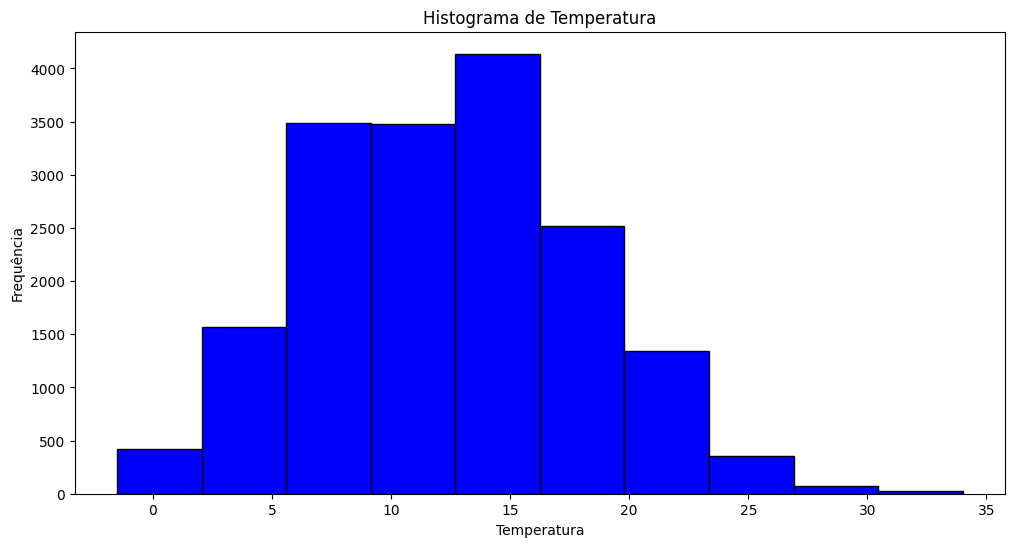

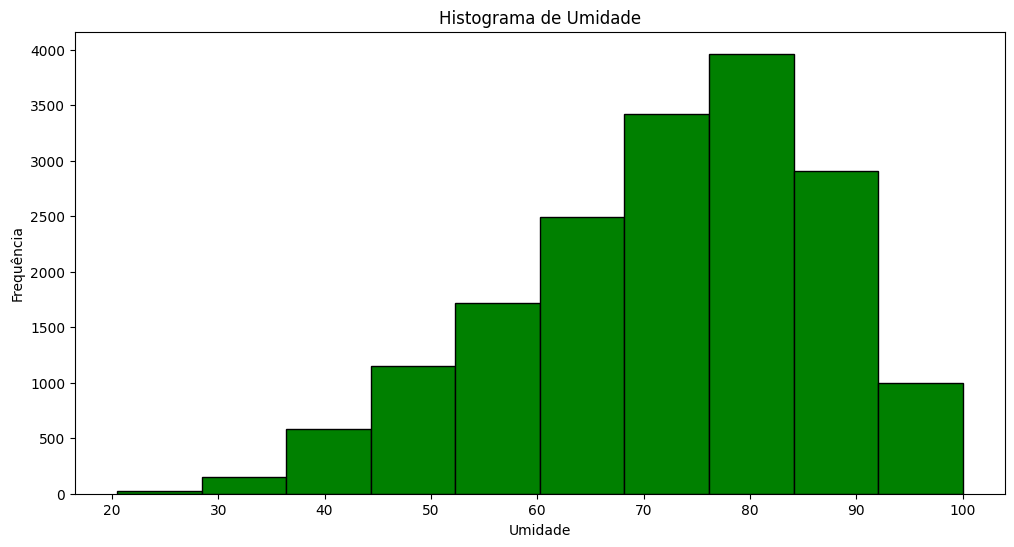

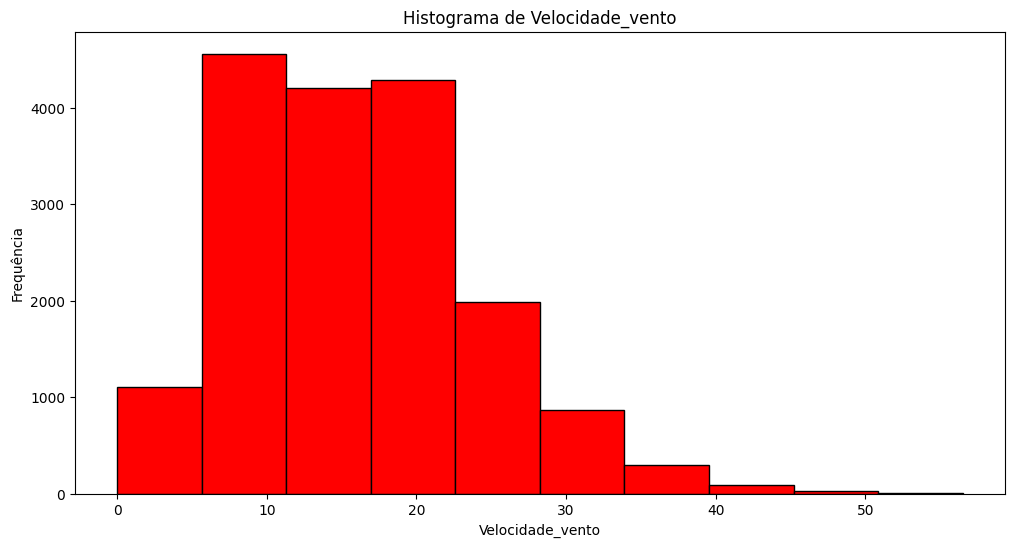

In [ ]:
plotar_histograma(df_limpo, 'temperatura', 'blue')
plotar_histograma(df_limpo, 'umidade', 'green')
plotar_histograma(df_limpo, 'velocidade_vento', 'red')

Text(0, 0.5, 'Contagem')

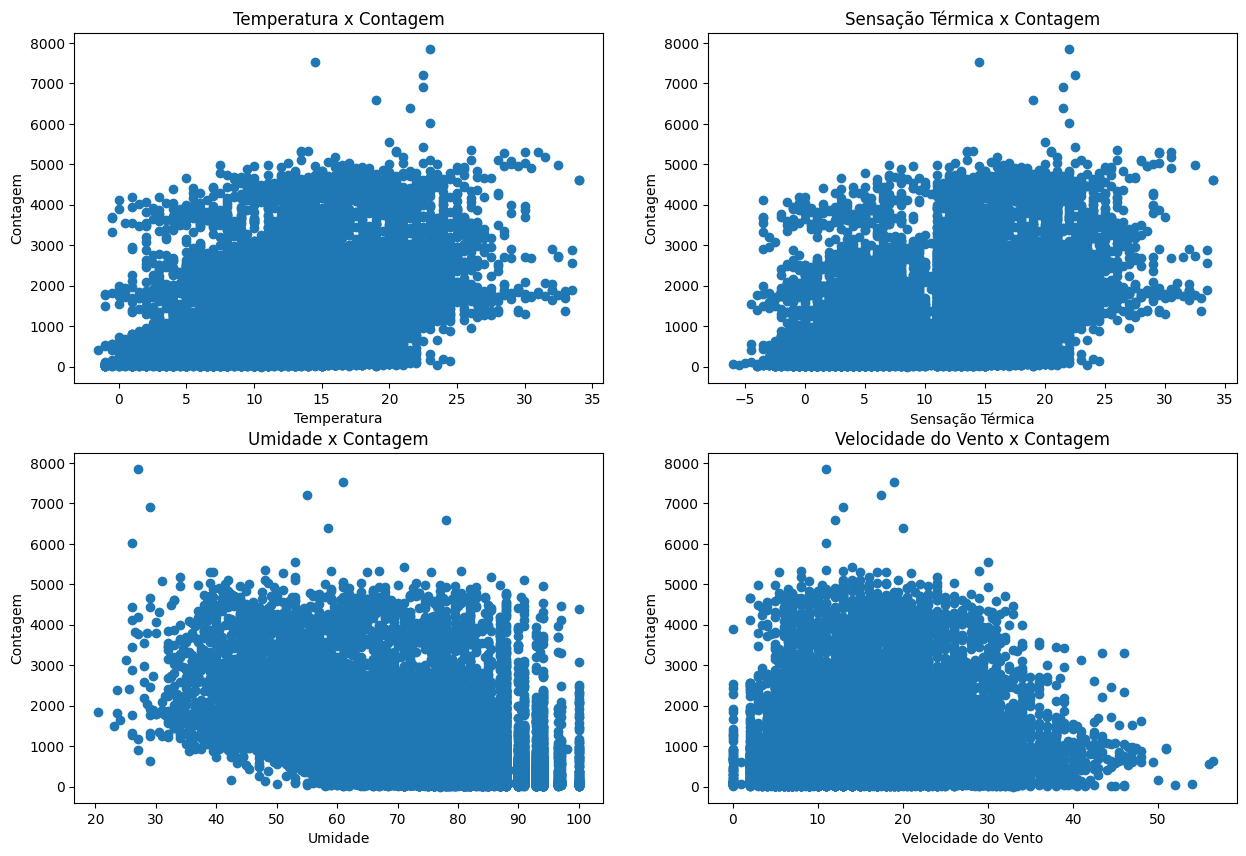

In [ ]:
# Relação entre variáveis climáticas e contagem de bicicletas
fig, axs = plt.subplots(2, 2, figsize=(15, 10))
axs[0, 0].scatter(df_limpo['temperatura'], df_limpo['contagem'])
axs[0, 0].set_title('Temperatura x Contagem')
axs[0, 0].set_xlabel('Temperatura')
axs[0, 0].set_ylabel('Contagem')

axs[0, 1].scatter(df_limpo['sensacao_termica'], df_limpo['contagem'])
axs[0, 1].set_title('Sensação Térmica x Contagem')
axs[0, 1].set_xlabel('Sensação Térmica')
axs[0, 1].set_ylabel('Contagem')

axs[1, 0].scatter(df_limpo['umidade'], df_limpo['contagem'])
axs[1, 0].set_title('Umidade x Contagem')
axs[1, 0].set_xlabel('Umidade')
axs[1, 0].set_ylabel('Contagem')

axs[1, 1].scatter(df_limpo['velocidade_vento'], df_limpo['contagem'])
axs[1, 1].set_title('Velocidade do Vento x Contagem')
axs[1, 1].set_xlabel('Velocidade do Vento')
axs[1, 1].set_ylabel('Contagem')

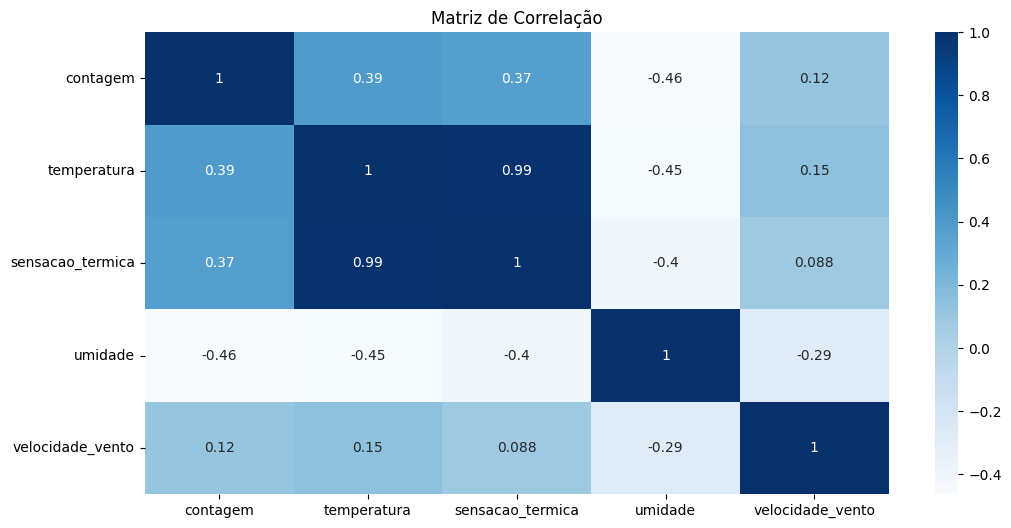

In [ ]:
# Mapa de calor da correlação entre variáveis numéricas
plt.figure(figsize=(12, 6))
matriz_corr = df_limpo.corr(numeric_only=True)
sns.heatmap(matriz_corr, annot=True, cmap='Blues')
plt.title('Matriz de Correlação')
plt.show()

In [ ]:
# Estatísticas descritivas para variáveis categóricas (object)
descritivas_obj = df_limpo.describe(include='object')
descritivas_obj

,data_hora,clima,feriado,fim_de_semana,estacao
count,17414,17414,17414,17414,17414
unique,17414,6,2,2,4
top,2017-01-03 23:00:00,Céu limpo,Não,Não,Primavera
freq,1,6150,17030,12444,4394


In [ ]:
for col in df_limpo.select_dtypes(include='object').columns:
  print(f'Coluna: {col}')
  print(df_limpo[col].unique())
  print('-'*50)

Coluna: data_hora
['2015-01-04 00:00:00' '2015-01-04 01:00:00' '2015-01-04 02:00:00' ...
 '2017-01-03 21:00:00' '2017-01-03 22:00:00' '2017-01-03 23:00:00']
--------------------------------------------------
Coluna: clima
['Nublado' 'Céu limpo' 'Parcialmente nublado' 'Chuva leve' 'Neve'
 'Chuva com trovoadas']
--------------------------------------------------
Coluna: feriado
['Não' 'Sim']
--------------------------------------------------
Coluna: fim_de_semana
['Sim' 'Não']
--------------------------------------------------
Coluna: estacao
['Inverno' 'Primavera' 'Verão' 'Outono']
--------------------------------------------------


In [ ]:
# Mediana de contagem em dias de feriado vs não feriado
mediana_feriado = df_limpo.groupby('feriado')['contagem'].median()
mediana_feriado

,contagem
feriado,
Não,855.0
Sim,439.5


In [ ]:
# Mediana de contagem em fim de semana vs dias de semana
mediana_fim_de_semana = df_limpo.groupby('fim_de_semana')['contagem'].median()
mediana_fim_de_semana

,contagem
fim_de_semana,
Não,927.0
Sim,619.0


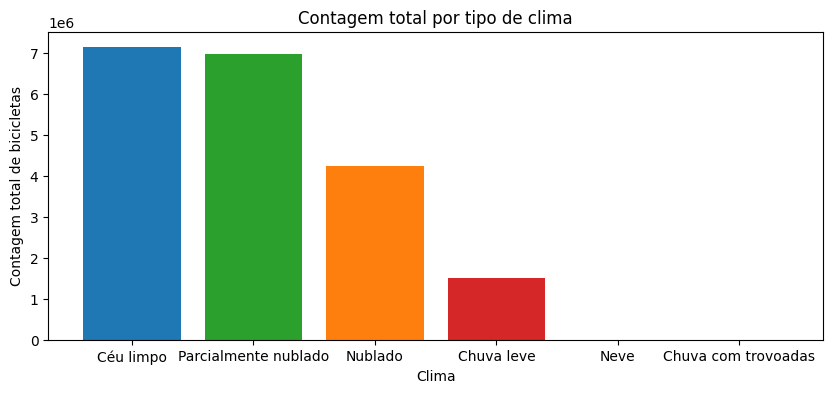

In [ ]:
# Contagem total por tipo de clima
df_clima = (df_limpo.groupby('clima')['contagem'].sum().sort_values(ascending=False).reset_index())
plt.figure(figsize=(10, 4))
cores = ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']
plt.bar(df_clima['clima'], df_clima['contagem'], color=cores[:len(df_clima)])
plt.xlabel('Clima')
plt.ylabel('Contagem total de bicicletas')
plt.title('Contagem total por tipo de clima')
plt.show()


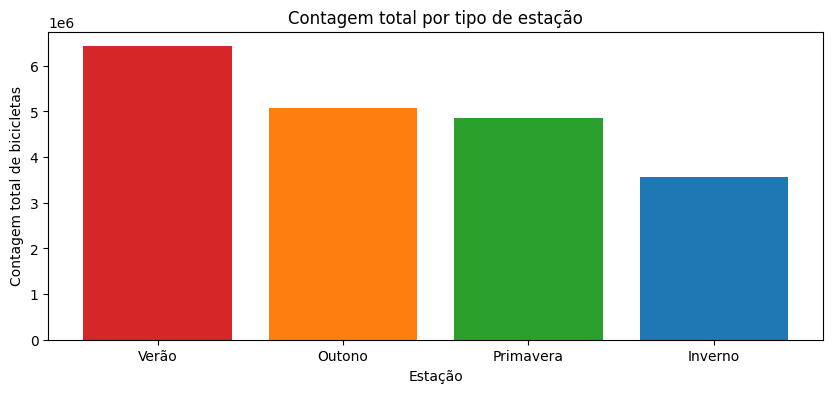

In [ ]:
# Contagem total por estação do ano
df_estacao = (df_limpo.groupby('estacao')['contagem'].sum().sort_values(ascending=False).reset_index())
plt.figure(figsize=(10, 4))
cores_estacoes = ['tab:red', 'tab:orange', 'tab:green', 'tab:blue']

plt.bar(df_estacao['estacao'], df_estacao['contagem'], color=cores_estacoes[:len(df_estacao)])
plt.xlabel('Estação')
plt.ylabel('Contagem total de bicicletas')
plt.title('Contagem total por tipo de estação')
plt.show()

In [ ]:
from scipy.stats import mannwhitneyu
# Separando as contagens de duas estações específicas
contagem_outono = df_limpo[df_limpo['estacao'] == 'Outono']['contagem']
contagem_primavera = df_limpo[df_limpo['estacao'] == 'Primavera']['contagem']

# Teste de Mann-Whitney U (não-paramétrico)
u_stats, p_value = mannwhitneyu(contagem_outono, contagem_primavera, alternative='two-sided')

print(f'Estatistica U: {u_stats}')
print(f'P-valor: {p_value}')

Estatistica U: 9862699.5
P-valor: 0.0004762100221646296
